# TripWorld feature experiments

Find which clues improve the top 10 recommendations. Call existing data loaders and evaluation code; do not edit ranking or retrieval.

**Plan**
1. Check inputs and missing/constant feature values.
2. On fold 0, compare corrected availability with the old calculation.
3. Remove one feature group at a time and retrain on identical training rows.
4. Repeat promising comparisons across folds, using the same candidate export for every variant within a fold.
5. Review score differences, uncertainty, cities, and example recommendations.

A correct formula does not guarantee better scores. Leave conclusions as **not measured** until experiments run. These are exploratory validation comparisons; reserve untouched users/folds for final confirmation before repeated tuning.


## Final decisions

We removed four context features (`tourist_ratio`, `dist_to_center_km`, `dest_cat_supply_share`, `dest_city_total_pois`) to simplify the model.
Five-fold testing with 10,000 sampled training records per fold found no clear performance difference.


## 1. Setup and settings

Run from the repository root or `notebooks/`. Use the ML environment with LightGBM, Matplotlib, and the repository requirements installed.

Start with fold 0 and 2,000 sampled training trips. This is a quick screen, not a final result. For confirmation, increase the training sample and provide matching candidates/statistics for every fold. Keep parameters fixed across variants. No early stopping or tuning on validation users.


In [1]:
from pathlib import Path
import os, sys, json, time, subprocess, importlib.metadata
import numpy as np
import pandas as pd
import duckdb
import lightgbm as lgb
import matplotlib.pyplot as plt
from tempfile import TemporaryDirectory

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
ROOT = Path.cwd().resolve()
if not (ROOT / "ml").is_dir():
    raise FileNotFoundError("Set the working directory to the repository root.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from ml.config import DATA_GOLD_DIR, RANDOM_SEED
from ml.ranking.train_ranker import load_joined_matrix
from ml.evaluate import evaluate_predictions

RUN_EXPERIMENTS = False  # Completed outputs below; use a new RUN_NAME for another run.
FOLDS = [0, 1, 2, 3, 4]
TRAIN_SAMPLE_TRIPS = 2_000
CANDIDATE_PATTERN = "candidates_popularity_top100_fold{fold}.parquet"
# Use hybrid exports instead if the team supplies them. Do not compare different
# candidate sets as if the difference came only from your features.
RUN_NAME = "feature_screen_all_folds"  # Use a new name for a different configuration.
OUT = ROOT / "reports" / "feature_experiments" / RUN_NAME
BOOTSTRAP_REPEATS = 500
PARAMS = dict(objective="lambdarank", metric="ndcg", lambdarank_truncation_level=13,
              n_estimators=300, learning_rate=0.05, num_leaves=63,
              subsample_for_bin=100_000, colsample_bytree=0.8,
              random_state=RANDOM_SEED, n_jobs=-1, verbosity=-1)

GROUPS = {
    "ratings": ["bayesian_rating", "has_google_rating", "log_google_reviews"],
    "popularity": ["log_n_checkins", "log_n_users", "log_train_tourist_visits", "city_pop_pct_rank"],
    "place_context": ["tourist_ratio", "dist_to_center_km", "dest_cat_supply_share", "dest_city_total_pois"],
    "user_preferences": ["user_cat_visits", "user_prior_travel_cat_visits", "user_cat_share", "user_cat_diversity"],
    "availability": ["avg_hist_supply_share", "opportunity_lift", "was_available_in_history"],
    "retrieval_signals": ["stage1_score", "stage1_rank", "sem_sim_mean", "sem_sim_max",
                          "sem_sim_top3", "sem_stage1a_score", "two_tower_score"],
}
# Keep history-size context in every variant; omit month in every variant.
# This notebook does not change the pipeline's existing history construction.
VARIANTS = ["full", "old_availability", *[f"without_{group}" for group in GROUPS]]


## 2. Input readiness

Use fold-specific POI statistics. City supply and taste must come from the corrected feature builder. The notebook never rebuilds shared data or candidates.

Missing inputs appear below. Ask the retrieval owner for matching all-fold candidate exports; run the feature builder for each requested fold. The legacy shared POI-statistics file is intentionally ignored.


In [2]:
required = {
    "catalog": DATA_GOLD_DIR / "pois_clean.parquet",
    "trips": DATA_GOLD_DIR / "trips_multicity.parquet",
    "folds": DATA_GOLD_DIR / "cv_folds.parquet",
    "targets": DATA_GOLD_DIR / "trip_targets_exploded.parquet",
    "history": DATA_GOLD_DIR / "trip_history_exploded.parquet",
    "supply": DATA_GOLD_DIR / "feat_city_supply.parquet",
    "taste": DATA_GOLD_DIR / "feat_user_locality_taste.parquet",
}
for fold in FOLDS:
    required[f"poi_stats_fold{fold}"] = DATA_GOLD_DIR / f"feat_poi_stats_fold{fold}.parquet"
    required[f"candidates_fold{fold}"] = DATA_GOLD_DIR / CANDIDATE_PATTERN.format(fold=fold)
readiness = pd.DataFrame([{"input": key, "ready": path.is_file(), "path": str(path.relative_to(ROOT))}
                          for key, path in required.items()])
display(readiness)
if not readiness["ready"].all():
    print("Not ready to train. No missing inputs will be created automatically.")


,input,ready,path
0,catalog,True,data/gold/pois_clean.parquet
1,trips,True,data/gold/trips_multicity.parquet
2,folds,True,data/gold/cv_folds.parquet
3,targets,True,data/gold/trip_targets_exploded.parquet
4,history,True,data/gold/trip_history_exploded.parquet
5,supply,True,data/gold/feat_city_supply.parquet
6,taste,True,data/gold/feat_user_locality_taste.parquet
7,poi_stats_fold0,True,data/gold/feat_poi_stats_fold0.parquet
8,candidates_fold0,True,data/gold/candidates_popularity_top100_fold0.p...
9,poi_stats_fold1,True,data/gold/feat_poi_stats_fold1.parquet


## 3. Comparison helpers

Retrain a fresh model for each comparison. Reuse the exact same sampled training rows and full validation candidates within a fold. Keep validation trips with no candidates in the metrics; they receive zero.

For the old-availability comparison, reconstruct the old average using only cities that offered the category, then change both the average and its derived lift. Missing joins follow the ranker's existing zero defaults.

Removing a group tests its extra contribution given the other groups. Related features can substitute for each other: “no clear improvement” does not prove a feature has no information. Removing popularity features also leaves the fixed retrieval candidate set unchanged, so this is a ranking comparison, not a full-system popularity removal.


In [3]:
def old_availability_lookup(train, val, categories):
    needed = pd.concat([train[["trip_id", "poi_id"]], val[["trip_id", "poi_id"]]], ignore_index=True)
    needed["venue_schema"] = needed["poi_id"].map(categories.set_index("poi_id")["venue_schema"])
    needed = needed[["trip_id", "venue_schema"]].drop_duplicates()
    # A small city-by-category grid avoids a large history/category SQL join.
    supply = pd.read_parquet(DATA_GOLD_DIR / "feat_city_supply.parquet")
    grid = supply.pivot(index="region_id", columns="venue_schema", values="city_supply_share").fillna(0)
    values = np.pad(grid.to_numpy(), ((0, 1), (0, 1)))
    city_index = {city: i for i, city in enumerate(grid.index)}
    category_index = {category: i for i, category in enumerate(grid.columns)}
    with duckdb.connect(config={"threads": 2, "memory_limit": "2GB"}) as con:
        cities = con.sql(f"SELECT DISTINCT trip_id, source_region_id FROM '{DATA_GOLD_DIR}/trip_history_exploded.parquet'").df()
    cities = cities[cities.trip_id.isin(needed.trip_id.unique())]
    city_lists = cities.groupby("trip_id")["source_region_id"].agg(list).to_dict()
    rows = []
    for trip_id, group in needed.groupby("trip_id", sort=False):
        city_ids = [city_index.get(city, len(grid)) for city in city_lists.get(trip_id, [])]
        category_ids = [category_index.get(category, len(grid.columns)) for category in group.venue_schema]
        offered = values[np.ix_(city_ids, category_ids)]
        counts = (offered > 0).sum(axis=0)
        averages = np.divide(offered.sum(axis=0), counts,
                             out=np.zeros(len(category_ids)), where=counts > 0)
        rows.extend(zip([trip_id] * len(group), group.venue_schema, averages))
    return pd.DataFrame(rows, columns=["trip_id", "venue_schema", "old_avg"])

def variant_matrix(frame, features, variant, old_lookup, categories):
    columns = [name for name in features if name != "dest_month"]
    if variant.startswith("without_"):
        removed = GROUPS[variant.removeprefix("without_")]
        columns = [name for name in columns if name not in removed]
    matrix = frame[columns].copy()
    if variant == "old_availability":
        category = frame["poi_id"].map(categories.set_index("poi_id")["venue_schema"])
        keys = pd.MultiIndex.from_arrays([frame["trip_id"], category], names=["trip_id", "venue_schema"])
        lookup = old_lookup.set_index(["trip_id", "venue_schema"])["old_avg"].reindex(keys)
        avg = np.where(frame["user_cat_visits"].to_numpy() > 0,
                       lookup.fillna(0).to_numpy(), 0.0)
        matrix["avg_hist_supply_share"] = avg
        # If taste has no row, user_cat_share is already zero in the loader.
        matrix["opportunity_lift"] = matrix["user_cat_share"].to_numpy() / (avg + 0.005)
    return matrix

def per_trip_metrics(predictions, fold):
    with duckdb.connect() as con:
        con.register("predictions", predictions)
        return con.sql(f"""
            WITH ranked AS (
                SELECT trip_id, poi_id,
                    ROW_NUMBER() OVER (PARTITION BY trip_id ORDER BY score DESC, poi_id) AS rank
                FROM predictions
            ), hits AS (
                SELECT p.trip_id, p.rank,
                    CASE WHEN y.poi_id IS NOT NULL THEN 1 ELSE 0 END AS hit
                FROM ranked p LEFT JOIN '{DATA_GOLD_DIR}/trip_targets_exploded.parquet' y
                    ON p.trip_id=y.trip_id AND p.poi_id=y.poi_id
                WHERE p.rank <= 10
            ), scores AS (
                SELECT trip_id, SUM(hit) AS hits,
                    SUM(hit / LOG2(rank + 1.0)) AS dcg FROM hits GROUP BY trip_id
            ), ideal AS (
                SELECT k, SUM(1.0 / LOG2(pos + 1.0)) AS idcg
                FROM range(1, 11) AS a(k), range(1, 11) AS b(pos)
                WHERE pos <= k GROUP BY k
            )
            SELECT t.trip_id, t.user_id, t.dest_region_id,
                COALESCE(s.dcg, 0) / i.idcg AS ndcg_10,
                COALESCE(s.hits, 0)::DOUBLE / t.n_target_pois AS recall_10
            FROM '{DATA_GOLD_DIR}/trips_multicity.parquet' t
            LEFT JOIN scores s ON t.trip_id=s.trip_id
            JOIN ideal i ON i.k=LEAST(t.n_target_pois, 10)
            WHERE t.fold={int(fold)}
        """).df()


## 4. Run comparisons

Set `RUN_EXPERIMENTS = True` when inputs are ready. Each variant is a separate model fit. Models are experiment-only and not deployed. Prediction files are temporary; reports and notebook outputs are retained.

Use a new run name when changing configuration. Completed fold results are checkpointed during the run.


In [4]:
results, paired_tables, quality_tables, example_tables = [], [], [], []
if RUN_EXPERIMENTS:
    if not readiness["ready"].all():
        raise FileNotFoundError("Complete the input-readiness table before training.")
    if OUT.exists():
        raise FileExistsError(f"Choose a new RUN_NAME; {OUT} already exists.")
    OUT.mkdir(parents=True)
    manifest = {
        "git_commit": subprocess.check_output(["git", "rev-parse", "HEAD"], text=True).strip(),
        "working_tree": subprocess.check_output(["git", "status", "--porcelain"], text=True),
        "folds": FOLDS, "training_trip_sample": TRAIN_SAMPLE_TRIPS, "parameters": PARAMS,
        "variants": VARIANTS, "groups": GROUPS, "candidate_pattern": CANDIDATE_PATTERN,
        "versions": {name: importlib.metadata.version(name) for name in ["lightgbm", "pandas", "duckdb", "numpy"]},
        "inputs": {key: {"path": str(path), "bytes": path.stat().st_size,
                          "modified_ns": path.stat().st_mtime_ns} for key, path in required.items()},
    }
    (OUT / "settings.json").write_text(json.dumps(manifest, indent=2))
    categories = pd.read_parquet(required["catalog"], columns=["poi_id", "venue_schema"])
    for fold in FOLDS:
        train, val, feature_names = load_joined_matrix(
            DATA_GOLD_DIR / CANDIDATE_PATTERN.format(fold=fold), fold,
            TRAIN_SAMPLE_TRIPS, gold_dir=DATA_GOLD_DIR)
        summary = train.groupby("trip_id", sort=False)["label"].agg(["size", "sum"])
        usable = summary["sum"].between(1, summary["size"] - 1)
        train = train[train["trip_id"].isin(summary.index[usable])].reset_index(drop=True)
        groups = train.groupby("trip_id", sort=False).size().to_numpy()
        if not len(groups):
            raise ValueError("No training groups contain both positive and negative candidates.")
        quality = pd.DataFrame({"feature": feature_names,
            "missing_fraction": train[feature_names].isna().mean().to_numpy(),
            "distinct_values": train[feature_names].nunique().to_numpy()}).assign(fold=fold)
        quality_tables.append(quality)
        old_lookup = old_availability_lookup(train, val, categories)
        print(f"Loaded fold {fold}: {len(train):,} training rows; {len(val):,} validation rows.")
        for variant in VARIANTS:
            if variant.startswith("without_") and not set(GROUPS[variant[8:]]) & set(feature_names):
                continue
            started = time.perf_counter()
            x_train = variant_matrix(train, feature_names, variant, old_lookup, categories)
            x_val = variant_matrix(val, feature_names, variant, old_lookup, categories)
            model = lgb.LGBMRanker(**PARAMS)
            model.fit(x_train, train["label"], group=groups, eval_at=(10,))
            predictions = val[["trip_id", "poi_id"]].assign(score=model.predict(x_val))
            with TemporaryDirectory(dir=OUT) as temporary:
                path = Path(temporary) / "predictions.parquet"
                predictions.to_parquet(path, index=False)
                official = evaluate_predictions(path, fold=fold)
            per_trip = per_trip_metrics(predictions, fold)
            assert np.isclose(per_trip.ndcg_10.mean(), official["ndcg_10"], atol=5.1e-6, rtol=0)
            assert np.isclose(per_trip.recall_10.mean(), official["recall_10"], atol=5.1e-6, rtol=0)
            paired_tables.append(per_trip.assign(fold=fold, variant=variant))
            # Fixed example trips selected by ID, not by which variant looks better.
            example_ids = sorted(val.trip_id.unique())[:3]
            examples = predictions[predictions.trip_id.isin(example_ids)].sort_values(
                ["trip_id", "score", "poi_id"], ascending=[True, False, True])
            examples = examples.groupby("trip_id", sort=False).head(10).copy()
            examples["rank"] = examples.groupby("trip_id").cumcount() + 1
            example_tables.append(examples.assign(fold=fold, variant=variant))
            results.append({"fold": fold, "variant": variant, **official,
                            "features": x_train.shape[1], "training_trips": len(groups),
                            "seconds": time.perf_counter() - started})
            pd.DataFrame(results).to_csv(OUT / "fold_scores.csv", index=False)
            print(f"Fold {fold}: {variant}: NDCG@10={official['ndcg_10']:.5f}")
        del train, val, x_train, x_val, predictions, model
        # Save completed folds as checkpoints during the longer multi-fold run.
        pd.concat(paired_tables).to_parquet(OUT / "paired_trip_scores.parquet", index=False)
        pd.concat(quality_tables).to_csv(OUT / "feature_quality.csv", index=False)
        pd.concat(example_tables).to_parquet(OUT / "example_rankings.parquet", index=False)
    pd.concat(paired_tables).to_parquet(OUT / "paired_trip_scores.parquet", index=False)
    pd.concat(quality_tables).to_csv(OUT / "feature_quality.csv", index=False)
    pd.concat(example_tables).to_parquet(OUT / "example_rankings.parquet", index=False)
else:
    print("Experiments are disabled. No usefulness claims or experiment reports have been generated.")


Candidate schema: trip_id BIGINT, user_id BIGINT, fold BIGINT, dest_region_id VARCHAR, dest_month INTEGER, n_history_cities BIGINT, n_history_pois BIGINT, poi_id VARCHAR, stage1_score DOUBLE, stage1_rank BIGINT
 fold  gold_trips  candidate_trips    rows  min_per_trip  median_per_trip  max_per_trip  trips_with_10
    0       89201            89201 8880988            51            100.0           100          89201
    1       88857            88857 8847370            51            100.0           100          88857
    2       87954            87954 8755694            51            100.0           100          87954
    3       90255            90255 8986223            51            100.0           100          90255
    4       88551            88551 8816564            51            100.0           100          88551


Loaded fold 0: 177,852 training rows; 8,880,988 validation rows.


Fold 0: full: NDCG@10=0.24794


Fold 0: old_availability: NDCG@10=0.25010


Fold 0: without_ratings: NDCG@10=0.24719


Fold 0: without_popularity: NDCG@10=0.24815


... (40 outputs left out)

Fold 4: without_place_context: NDCG@10=0.25461


Fold 4: without_user_preferences: NDCG@10=0.25072


Fold 4: without_availability: NDCG@10=0.25201


Fold 4: without_retrieval_signals: NDCG@10=0.25502


## 5. Results and uncertainty

Primary metric: **NDCG@10** (relevant places near the top). Also inspect Recall@10, catalog coverage, diversity, and runtime. The score table averages folds equally; paired uncertainty uses all trips and resamples users so one user's trips stay together.

For each comparison below, positive means **full model minus comparison model**. A positive difference for `without_ratings` supports keeping ratings. A positive difference for `old_availability` supports the correction.

A 95% interval spanning zero means **uncertain**, not useless. Intervals are exploratory, not adjusted for many comparisons, and do not include uncertainty from retraining across random seeds. Confirm small gains on more folds/seeds and untouched data. Shared candidate generation must also follow the team's fold-safety rules.


,fold,variant,ndcg_10,recall_10,coverage_10,diversity_10,seconds
0,0,full,0.24794,0.33151,0.06379,6.125,12.564665
1,0,old_availability,0.25010,0.33500,0.06306,6.170,14.910789
2,0,without_ratings,0.24719,0.33295,0.06316,6.101,12.348513
3,0,without_popularity,0.24815,0.33339,0.06158,6.176,12.533508
4,0,without_place_context,0.25222,0.33861,0.06492,6.136,12.671376
5,0,without_user_preferences,0.24740,0.33268,0.05846,6.247,12.932658
6,0,without_availability,0.25020,0.33608,0.05661,6.239,12.705795
7,0,without_retrieval_signals,0.24919,0.33449,0.06276,6.186,12.776386
8,1,full,0.25121,0.33249,0.06002,6.255,13.160919
9,1,old_availability,0.25157,0.33369,0.06036,6.127,14.688813


ndcg_10           recall_10          
                               mean       std      mean       std
variant                                                          
full                       0.251542  0.003986  0.334526  0.004243
old_availability           0.250484  0.002563  0.334018  0.002842
without_availability       0.250476  0.002368  0.334424  0.002734
without_place_context      0.252646  0.002462  0.336972  0.003899
without_popularity         0.251378  0.002585  0.334164  0.002628
without_ratings            0.251008  0.003445  0.334514  0.003665
without_retrieval_signals  0.251390  0.003138  0.335298  0.003171
without_user_preferences   0.248336  0.001891  0.332292  0.002375

,comparison,ndcg_difference,low_95,high_95,folds_improved,folds_tested,evidence
0,old_availability,0.001046,0.000719,0.001391,3,5,supports full
1,without_availability,0.001058,0.000676,0.001423,4,5,supports full
2,without_place_context,-0.001115,-0.001502,-0.000705,2,5,supports comparison
3,without_popularity,0.000144,-0.000206,0.000474,3,5,uncertain
4,without_ratings,0.000529,0.000150,0.000925,3,5,supports full
5,without_retrieval_signals,0.000147,-0.000196,0.000526,3,5,uncertain
6,without_user_preferences,0.003193,0.002837,0.003561,5,5,supports full


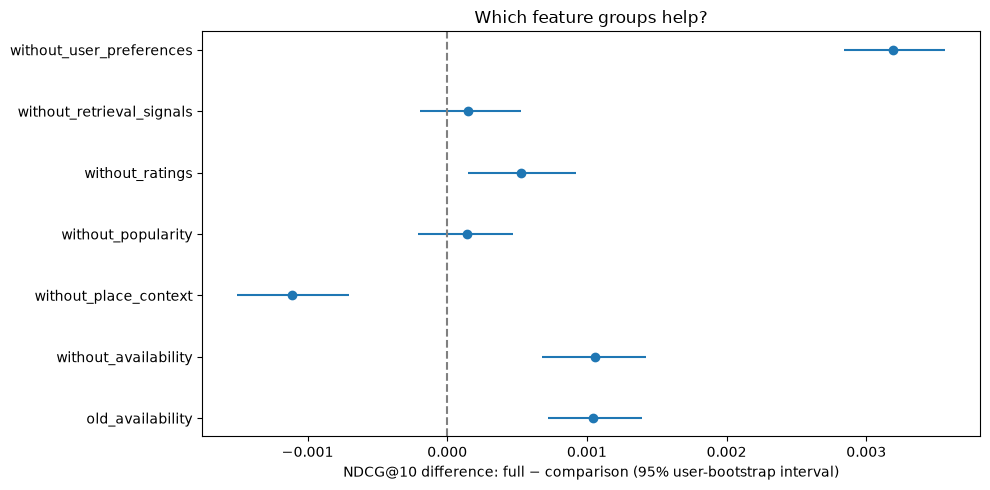

In [5]:
if (OUT / "fold_scores.csv").exists() and (OUT / "paired_trip_scores.parquet").exists():
    scores = pd.read_csv(OUT / "fold_scores.csv")
    paired = pd.read_parquet(OUT / "paired_trip_scores.parquet")
    display(scores[["fold", "variant", "ndcg_10", "recall_10", "coverage_10", "diversity_10", "seconds"]])
    display(scores.groupby("variant")[["ndcg_10", "recall_10"]].agg(["mean", "std"]))
    full = paired[paired.variant == "full"]
    comparisons = []
    for variant in sorted(set(paired.variant) - {"full"}):
        other = paired[paired.variant == variant]
        delta = full.merge(other, on=["fold", "trip_id", "user_id", "dest_region_id"],
                           suffixes=("_full", "_other"), validate="one_to_one")
        delta["difference"] = delta.ndcg_10_full - delta.ndcg_10_other
        users = delta.groupby("user_id")["difference"].agg(["sum", "count"])
        rng = np.random.default_rng(RANDOM_SEED)
        samples = []
        for _ in range(BOOTSTRAP_REPEATS):
            selected = users.iloc[rng.integers(0, len(users), size=len(users))]
            samples.append(selected["sum"].sum() / selected["count"].sum())
        low, high = np.quantile(samples, [0.025, 0.975])
        fold_deltas = delta.groupby("fold")["difference"].mean()
        comparisons.append({"comparison": variant, "ndcg_difference": delta.difference.mean(),
            "low_95": low, "high_95": high, "folds_improved": int((fold_deltas > 0).sum()),
            "folds_tested": len(fold_deltas),
            "evidence": "supports full" if low > 0 else "supports comparison" if high < 0 else "uncertain"})
    differences = pd.DataFrame(comparisons)
    display(differences)
    differences.to_csv(OUT / "comparison_summary.csv", index=False)
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.errorbar(differences.ndcg_difference, differences.comparison,
                xerr=[differences.ndcg_difference-differences.low_95,
                      differences.high_95-differences.ndcg_difference], fmt="o")
    ax.axvline(0, color="gray", linestyle="--")
    ax.set(xlabel="NDCG@10 difference: full − comparison (95% user-bootstrap interval)",
           ylabel="", title="Which feature groups help?")
    fig.tight_layout()
    fig.savefig(OUT / "feature_comparison.png", dpi=160)
    plt.show()
else:
    print("Not measured yet. Run complete comparisons before drawing conclusions.")


## 6. Cities, feature quality, and examples

Check whether an average gain hides losses in smaller cities. Read missing/constant features before blaming the model. Compare the same users' top 10 across variants; plausible-looking examples illustrate behavior but do not establish a gain.


In [6]:
if (OUT / "paired_trip_scores.parquet").exists():
    paired = pd.read_parquet(OUT / "paired_trip_scores.parquet")
    cities = paired.groupby(["variant", "dest_region_id"]).agg(
        trips=("trip_id", "size"), ndcg_10=("ndcg_10", "mean"), recall_10=("recall_10", "mean")).reset_index()
    display(cities.sort_values(["variant", "trips"], ascending=[True, False]).groupby("variant").head(10))
    cities.to_csv(OUT / "city_scores.csv", index=False)
    quality = pd.read_csv(OUT / "feature_quality.csv")
    display(quality.sort_values(["missing_fraction", "distinct_values"], ascending=[False, True]))
    examples = pd.read_parquet(OUT / "example_rankings.parquet")
    catalog = pd.read_parquet(required["catalog"], columns=["poi_id", "name", "venue_schema"])
    display(examples.merge(catalog, on="poi_id", how="left", validate="many_to_one"))
else:
    print("City comparisons and examples will appear after experiments run.")


,variant,dest_region_id,trips,ndcg_10,recall_10
549,full,Q35765,16706,0.056438,0.076177
129,full,Q1490,11912,0.057993,0.074840
48,full,Q11751,9840,0.110671,0.154670
602,full,Q406,6920,0.063877,0.086725
376,full,Q26600,5105,0.130939,0.183983
...,...,...,...,...,...
8706,without_user_preferences,Q35997,4386,0.129319,0.174892
8790,without_user_preferences,Q46747,4116,0.129654,0.186021
8616,without_user_preferences,Q31873774,3965,0.583827,0.677775
8727,without_user_preferences,Q37951,3703,0.101363,0.138372


,feature,missing_fraction,distinct_values,fold
6,has_google_rating,0.0,2,0
21,was_available_in_history,0.0,2,0
29,has_google_rating,0.0,2,1
44,was_available_in_history,0.0,2,1
52,has_google_rating,0.0,2,2
...,...,...,...,...
81,dist_to_center_km,0.0,61133,3
12,dist_to_center_km,0.0,61663,0
58,dist_to_center_km,0.0,61857,2
35,dist_to_center_km,0.0,62666,1


,trip_id,poi_id,score,rank,fold,variant,name,venue_schema
0,5,foursquare:4bb4fc54eb6dd13a0c9d96e4,1.458735,1,0,full,Starbucks,schema:CafeOrCoffeeShop
1,5,foursquare:4cfe905466ee9eb06ae2a64e,1.388857,2,0,full,The Regency Hotel,schema:Hotel
2,5,foursquare:4c78eaf6794e224b79ab6328,0.892501,3,0,full,Rumaithiya Co-op,schema:DepartmentStore
3,5,foursquare:4c34803566e40f476a95c98b,0.881776,4,0,full,TGI Friday's | Al-Bidaa,schema:Restaurant
4,5,foursquare:4ba4f204f964a520acc638e3,0.470102,5,0,full,The Chocolate Bar – Argan Al Bidaa,schema:CafeOrCoffeeShop
...,...,...,...,...,...,...,...,...
1195,21,foursquare:4c06a30d2e80a593c36c74f9,-0.149926,6,4,without_retrieval_signals,Festival Cafe,schema:CafeOrCoffeeShop
1196,21,foursquare:4f8da957e4b0375890e0183e,-0.260511,7,4,without_retrieval_signals,Geppetto,schema:Restaurant
1197,21,foursquare:5658498538fae34673bf6961,-0.419538,8,4,without_retrieval_signals,Geyikmod,schema:BarOrPub
1198,21,foursquare:5805e5c2d67cabafe99050df,-0.441349,9,4,without_retrieval_signals,Para Cafe & Restaurant,schema:CafeOrCoffeeShop


## 7. What all five folds tell us

Completed **40 comparisons**: eight variants on five user-disjoint folds. Every variant within a fold used the same candidates, training records, and model settings. The training sample budget stayed at 2,000 records per fold; all 444,818 validation records were evaluated once across the five folds.

Higher NDCG@10 is better. The full model's mean score was **0.25154**.

| Clues being tested | Mean score without them | Full model better on | What to do next |
| --- | --- | --- | --- |
| User-category preferences | 0.24834 | 5/5 folds | Strongest evidence of usefulness; keep |
| Availability features | 0.25048 | 4/5 folds | Small average benefit; keep and confirm with more training data |
| Ratings/review information | 0.25101 | 3/5 folds | Small average benefit; keep provisionally |
| Popularity features | 0.25138 | 3/5 folds | Extra benefit uncertain; do not remove yet |
| Retrieval scores/ranks | 0.25139 | 3/5 folds | Extra benefit uncertain; candidate lists stayed fixed |
| Place context | 0.25265 | 2/5 folds | Removing this group improved the average; test its pieces separately |

**Old versus corrected availability:** the old formula averaged **0.25048**, compared with **0.25154** for the corrected formula. The correction helped on 3/5 folds. It is a small gain, not a guarantee of better results for every split.

The paired user-bootstrap intervals support an average benefit for user preferences, availability, the corrected formula, and ratings; they support an average loss for the combined place-context group. Popularity and retrieval-score intervals include zero. These intervals do not include training-sample/seed variability and are not adjusted for trying several comparisons.

**Next experiment:** separate tourist ratio, distance, and city-supply features within place context. Keep the other groups fixed. Confirm the strongest findings with a larger training sample and fresh seeds before changing shared model inputs. Group results do not establish whether every individual column helps.

Reports: `reports/feature_experiments/feature_screen_all_folds/`. Training is disabled again to preserve these outputs. Choose a new `RUN_NAME` before another run.


## 8. Which place-context clues help?

Separate the group into tourist ratio, distance, and city supply. Remove one piece at a time; keep every other feature unchanged. Also rerun the full model and removal of the whole group to check the previous result.

Use the same five folds, candidates, training sample, and parameters. This follow-up uses validation results already inspected, so it is exploratory; a larger sample and fresh seeds are needed before changing the shared model.


In [4]:
RUN_CONTEXT_EXPERIMENTS = False  # Completed outputs are saved below.
CONTEXT_OUT = ROOT / "reports" / "feature_experiments" / "place_context_screen_all_folds"
CONTEXT_GROUPS = {
    "tourist_ratio": ["tourist_ratio"],
    "distance": ["dist_to_center_km"],
    "city_supply": ["dest_cat_supply_share", "dest_city_total_pois"],
    "place_context": ["tourist_ratio", "dist_to_center_km", "dest_cat_supply_share", "dest_city_total_pois"],
}
CONTEXT_VARIANTS = ["full", *[f"without_{group}" for group in CONTEXT_GROUPS]]

def context_variant_matrix(frame, features, variant):
    columns = [name for name in features if name != "dest_month"]
    if variant.startswith("without_"):
        removed = CONTEXT_GROUPS[variant.removeprefix("without_")]
        columns = [name for name in columns if name not in removed]
    return frame[columns].copy()


In [5]:
results, paired_tables, quality_tables, example_tables = [], [], [], []
if RUN_CONTEXT_EXPERIMENTS:
    if not readiness["ready"].all():
        raise FileNotFoundError("Complete the input-readiness table before training.")
    if CONTEXT_OUT.exists():
        raise FileExistsError(f"Choose a new RUN_NAME; {CONTEXT_OUT} already exists.")
    CONTEXT_OUT.mkdir(parents=True)
    manifest = {
        "git_commit": subprocess.check_output(["git", "rev-parse", "HEAD"], text=True).strip(),
        "working_tree": subprocess.check_output(["git", "status", "--porcelain"], text=True),
        "folds": FOLDS, "training_trip_sample": TRAIN_SAMPLE_TRIPS, "parameters": PARAMS,
        "variants": CONTEXT_VARIANTS, "groups": CONTEXT_GROUPS, "candidate_pattern": CANDIDATE_PATTERN,
        "versions": {name: importlib.metadata.version(name) for name in ["lightgbm", "pandas", "duckdb", "numpy"]},
        "inputs": {key: {"path": str(path), "bytes": path.stat().st_size,
                          "modified_ns": path.stat().st_mtime_ns} for key, path in required.items()},
    }
    (CONTEXT_OUT / "settings.json").write_text(json.dumps(manifest, indent=2))
    for fold in FOLDS:
        train, val, feature_names = load_joined_matrix(
            DATA_GOLD_DIR / CANDIDATE_PATTERN.format(fold=fold), fold,
            TRAIN_SAMPLE_TRIPS, gold_dir=DATA_GOLD_DIR)
        summary = train.groupby("trip_id", sort=False)["label"].agg(["size", "sum"])
        usable = summary["sum"].between(1, summary["size"] - 1)
        train = train[train["trip_id"].isin(summary.index[usable])].reset_index(drop=True)
        groups = train.groupby("trip_id", sort=False).size().to_numpy()
        if not len(groups):
            raise ValueError("No training groups contain both positive and negative candidates.")
        quality = pd.DataFrame({"feature": feature_names,
            "missing_fraction": train[feature_names].isna().mean().to_numpy(),
            "distinct_values": train[feature_names].nunique().to_numpy()}).assign(fold=fold)
        quality_tables.append(quality)
        print(f"Loaded fold {fold}: {len(train):,} training rows; {len(val):,} validation rows.")
        for variant in CONTEXT_VARIANTS:
            if variant.startswith("without_") and not set(CONTEXT_GROUPS[variant[8:]]) & set(feature_names):
                continue
            started = time.perf_counter()
            x_train = context_variant_matrix(train, feature_names, variant)
            x_val = context_variant_matrix(val, feature_names, variant)
            model = lgb.LGBMRanker(**PARAMS)
            model.fit(x_train, train["label"], group=groups, eval_at=(10,))
            predictions = val[["trip_id", "poi_id"]].assign(score=model.predict(x_val))
            with TemporaryDirectory(dir=CONTEXT_OUT) as temporary:
                path = Path(temporary) / "predictions.parquet"
                predictions.to_parquet(path, index=False)
                official = evaluate_predictions(path, fold=fold)
            per_trip = per_trip_metrics(predictions, fold)
            assert np.isclose(per_trip.ndcg_10.mean(), official["ndcg_10"], atol=5.1e-6, rtol=0)
            assert np.isclose(per_trip.recall_10.mean(), official["recall_10"], atol=5.1e-6, rtol=0)
            paired_tables.append(per_trip.assign(fold=fold, variant=variant))
            # Fixed example trips selected by ID, not by which variant looks better.
            example_ids = sorted(val.trip_id.unique())[:3]
            examples = predictions[predictions.trip_id.isin(example_ids)].sort_values(
                ["trip_id", "score", "poi_id"], ascending=[True, False, True])
            examples = examples.groupby("trip_id", sort=False).head(10).copy()
            examples["rank"] = examples.groupby("trip_id").cumcount() + 1
            example_tables.append(examples.assign(fold=fold, variant=variant))
            results.append({"fold": fold, "variant": variant, **official,
                            "features": x_train.shape[1], "training_trips": len(groups),
                            "seconds": time.perf_counter() - started})
            pd.DataFrame(results).to_csv(CONTEXT_OUT / "fold_scores.csv", index=False)
            print(f"Fold {fold}: {variant}: NDCG@10={official['ndcg_10']:.5f}")
        del train, val, x_train, x_val, predictions, model
        # Save completed folds as checkpoints during the longer multi-fold run.
        pd.concat(paired_tables).to_parquet(CONTEXT_OUT / "paired_trip_scores.parquet", index=False)
        pd.concat(quality_tables).to_csv(CONTEXT_OUT / "feature_quality.csv", index=False)
        pd.concat(example_tables).to_parquet(CONTEXT_OUT / "example_rankings.parquet", index=False)
    pd.concat(paired_tables).to_parquet(CONTEXT_OUT / "paired_trip_scores.parquet", index=False)
    pd.concat(quality_tables).to_csv(CONTEXT_OUT / "feature_quality.csv", index=False)
    pd.concat(example_tables).to_parquet(CONTEXT_OUT / "example_rankings.parquet", index=False)
else:
    print("Experiments are disabled. No usefulness claims or experiment reports have been generated.")


Candidate schema: trip_id BIGINT, user_id BIGINT, fold BIGINT, dest_region_id VARCHAR, dest_month INTEGER, n_history_cities BIGINT, n_history_pois BIGINT, poi_id VARCHAR, stage1_score DOUBLE, stage1_rank BIGINT
 fold  gold_trips  candidate_trips    rows  min_per_trip  median_per_trip  max_per_trip  trips_with_10
    0       89201            89201 8880988            51            100.0           100          89201
    1       88857            88857 8847370            51            100.0           100          88857
    2       87954            87954 8755694            51            100.0           100          87954
    3       90255            90255 8986223            51            100.0           100          90255
    4       88551            88551 8816564            51            100.0           100          88551


Loaded fold 0: 177,852 training rows; 8,880,988 validation rows.


Fold 0: full: NDCG@10=0.24794


Fold 0: without_tourist_ratio: NDCG@10=0.25226


Fold 0: without_distance: NDCG@10=0.24897


Fold 0: without_city_supply: NDCG@10=0.24855


... (25 outputs left out)

Fold 4: without_tourist_ratio: NDCG@10=0.25424


Fold 4: without_distance: NDCG@10=0.25656


Fold 4: without_city_supply: NDCG@10=0.25811


Fold 4: without_place_context: NDCG@10=0.25461


## 9. Place-context results

Positive differences mean the full model is better; negative differences mean removing that piece is better. Check the average, uncertainty range, and number of folds together. A group can look useful in isolation but redundant alongside other features.


,fold,variant,ndcg_10,recall_10,coverage_10,diversity_10,seconds
0,0,full,0.24794,0.33151,0.06379,6.125,12.567864
1,0,without_tourist_ratio,0.25226,0.33687,0.06167,6.177,12.942850
2,0,without_distance,0.24897,0.33313,0.06456,6.139,12.647193
3,0,without_city_supply,0.24855,0.33483,0.06598,6.156,12.443048
4,0,without_place_context,0.25222,0.33861,0.06492,6.136,12.549458
5,1,full,0.25121,0.33249,0.06002,6.255,13.359892
6,1,without_tourist_ratio,0.25344,0.33523,0.05870,6.157,12.994650
7,1,without_distance,0.24910,0.32964,0.06129,6.191,12.619675
8,1,without_city_supply,0.25015,0.33175,0.06322,6.161,12.714982
9,1,without_place_context,0.25001,0.33163,0.06632,6.155,12.336600


ndcg_10           recall_10          
                           mean       std      mean       std
variant                                                      
full                   0.251542  0.003986  0.334526  0.004243
without_city_supply    0.251704  0.003938  0.335266  0.003660
without_distance       0.251710  0.003461  0.334270  0.003640
without_place_context  0.252646  0.002462  0.336972  0.003899
without_tourist_ratio  0.251926  0.003131  0.334968  0.003045

,comparison,ndcg_difference,low_95,high_95,folds_improved,folds_tested,evidence
0,without_city_supply,-0.000171,-0.000519,0.000185,2,5,uncertain
1,without_distance,-0.000175,-0.000505,0.000212,2,5,uncertain
2,without_place_context,-0.001115,-0.001502,-0.000705,2,5,supports comparison
3,without_tourist_ratio,-0.000387,-0.000733,-0.000066,3,5,supports comparison


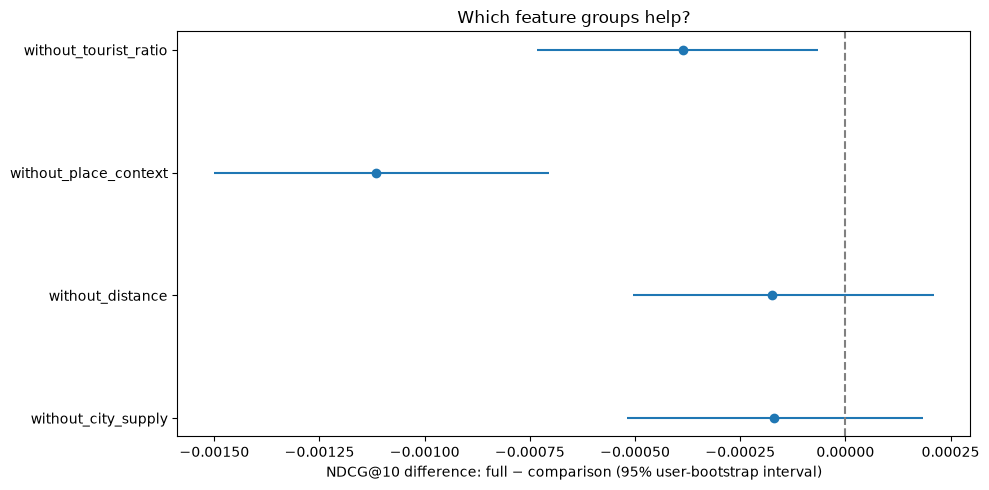

In [6]:
if (CONTEXT_OUT / "fold_scores.csv").exists() and (CONTEXT_OUT / "paired_trip_scores.parquet").exists():
    scores = pd.read_csv(CONTEXT_OUT / "fold_scores.csv")
    paired = pd.read_parquet(CONTEXT_OUT / "paired_trip_scores.parquet")
    display(scores[["fold", "variant", "ndcg_10", "recall_10", "coverage_10", "diversity_10", "seconds"]])
    display(scores.groupby("variant")[["ndcg_10", "recall_10"]].agg(["mean", "std"]))
    full = paired[paired.variant == "full"]
    comparisons = []
    for variant in sorted(set(paired.variant) - {"full"}):
        other = paired[paired.variant == variant]
        delta = full.merge(other, on=["fold", "trip_id", "user_id", "dest_region_id"],
                           suffixes=("_full", "_other"), validate="one_to_one")
        delta["difference"] = delta.ndcg_10_full - delta.ndcg_10_other
        users = delta.groupby("user_id")["difference"].agg(["sum", "count"])
        rng = np.random.default_rng(RANDOM_SEED)
        samples = []
        for _ in range(BOOTSTRAP_REPEATS):
            selected = users.iloc[rng.integers(0, len(users), size=len(users))]
            samples.append(selected["sum"].sum() / selected["count"].sum())
        low, high = np.quantile(samples, [0.025, 0.975])
        fold_deltas = delta.groupby("fold")["difference"].mean()
        comparisons.append({"comparison": variant, "ndcg_difference": delta.difference.mean(),
            "low_95": low, "high_95": high, "folds_improved": int((fold_deltas > 0).sum()),
            "folds_tested": len(fold_deltas),
            "evidence": "supports full" if low > 0 else "supports comparison" if high < 0 else "uncertain"})
    differences = pd.DataFrame(comparisons)
    display(differences)
    differences.to_csv(CONTEXT_OUT / "comparison_summary.csv", index=False)
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.errorbar(differences.ndcg_difference, differences.comparison,
                xerr=[differences.ndcg_difference-differences.low_95,
                      differences.high_95-differences.ndcg_difference], fmt="o")
    ax.axvline(0, color="gray", linestyle="--")
    ax.set(xlabel="NDCG@10 difference: full − comparison (95% user-bootstrap interval)",
           ylabel="", title="Which feature groups help?")
    fig.tight_layout()
    fig.savefig(CONTEXT_OUT / "feature_comparison.png", dpi=160)
    plt.show()
else:
    print("Not measured yet. Run complete comparisons before drawing conclusions.")


## 10. What the place-context tests tell us

Completed 25 fits across the same five folds. Reference scores exactly match the first experiment, confirming that the comparison settings were preserved. Higher NDCG@10 is better.

| Experiment | Mean NDCG@10 | Removal helped on | Finding |
| --- | --- | --- | --- |
| Full model | 0.25154 | — | Reference |
| Remove tourist ratio | 0.25193 | 2/5 folds | Small average gain, but inconsistent |
| Remove distance | 0.25171 | 3/5 folds | Difference uncertain |
| Remove city supply | 0.25170 | 3/5 folds | Difference uncertain |
| Remove all place context | 0.25265 | 3/5 folds | Larger average gain; group interaction needs investigation |

The paired user-bootstrap interval supports the small average gain from removing tourist ratio on these fitted models; it spans zero for distance and city supply. Tourist ratio still helps on three folds, so the two removal gains dominate the average. A positive average does not mean every fold improves.

**Recommendation:** do not delete any feature yet. Tourist ratio is the first calculation to review: its local-visit count comes from repeated per-example home histories, which can overcount a user's local activity. That issue needs a separate correction/test, not an automatic removal. Repeat the strongest comparisons with more training records and fresh seeds. Keep city supply and distance while their benefit remains uncertain.

These are exploratory comparisons on previously inspected folds, with one seed and a small training sample. No changes were made to feature calculations, ranking, retrieval, or the deployed model.

Outputs: `reports/feature_experiments/place_context_screen_all_folds/`. Experiment execution is disabled again; saved tables and charts remain visible. Use a new output directory when rerunning.


## 11. Count local users once in tourist ratio

The current feature counts one home POI again for every training example containing it. A person with many destination records can therefore contribute several local visits for the same POI.

Test a narrow correction: count each training user–home-POI pair once. Keep tourist counts, smoothing, candidates, other features, and training settings unchanged. This measures distinct local users, not the number of physical check-in events. Validation users never contribute.

Compare current ratio, corrected ratio, and no ratio on all five folds. This is an experiment only; shared feature files are not rewritten.


In [4]:
RUN_RATIO_EXPERIMENTS = False  # Completed outputs are saved below.
RATIO_OUT = ROOT / "reports" / "feature_experiments" / "tourist_ratio_unique_locals_all_folds"
RATIO_VARIANTS = ["full", "corrected_tourist_ratio", "without_tourist_ratio"]

def corrected_tourist_ratios(fold, gold_dir=DATA_GOLD_DIR):
    with duckdb.connect() as con:
        return con.sql(f"""
            WITH locals AS (
                SELECT poi_id, COUNT(*) AS local_rows, COUNT(DISTINCT user_id) AS local_users
                FROM '{gold_dir}/trip_history_exploded.parquet'
                WHERE fold != {int(fold)} AND is_home = TRUE GROUP BY poi_id
            ), tourists AS (
                SELECT poi_id, COUNT(*) AS tourist_visits
                FROM '{gold_dir}/trip_targets_exploded.parquet'
                WHERE fold != {int(fold)} GROUP BY poi_id
            )
            SELECT p.poi_id, COALESCE(l.local_rows, 0) AS local_rows,
                COALESCE(l.local_users, 0) AS local_users,
                (COALESCE(t.tourist_visits, 0) + 1.0)
                    / (COALESCE(t.tourist_visits, 0) + COALESCE(l.local_rows, 0) + 5.0) AS current_ratio,
                (COALESCE(t.tourist_visits, 0) + 1.0)
                    / (COALESCE(t.tourist_visits, 0) + COALESCE(l.local_users, 0) + 5.0) AS corrected_ratio
            FROM '{gold_dir}/pois_clean.parquet' p
            LEFT JOIN locals l ON p.poi_id=l.poi_id LEFT JOIN tourists t ON p.poi_id=t.poi_id
        """).df()

def ratio_variant_matrix(frame, features, variant, lookup):
    columns = [name for name in features if name != "dest_month"]
    if variant == "without_tourist_ratio":
        columns.remove("tourist_ratio")
    matrix = frame[columns].copy()
    if variant == "corrected_tourist_ratio":
        values = frame.poi_id.map(lookup.set_index("poi_id").corrected_ratio)
        if values.isna().any():
            raise ValueError("A candidate POI is missing from the ratio lookup.")
        matrix["tourist_ratio"] = values.to_numpy()
    return matrix


### Check the correction on a small example

Three copies of one training user's home visit count as one local user. Adding copies of a validation user's visits must change neither ratio.


In [5]:
with TemporaryDirectory() as directory:
    toy = Path(directory)
    pd.DataFrame({"poi_id": ["museum"]}).to_parquet(toy / "pois_clean.parquet", index=False)
    pd.DataFrame({"poi_id": ["museum"], "fold": [1]}).to_parquet(toy / "trip_targets_exploded.parquet", index=False)
    history = pd.DataFrame({"poi_id": ["museum"] * 4, "user_id": [1, 1, 1, 9],
                            "fold": [1, 1, 1, 0], "is_home": [True] * 4})
    history.to_parquet(toy / "trip_history_exploded.parquet", index=False)
    first = corrected_tourist_ratios(0, toy)
    assert first.local_rows.iloc[0] == 3 and first.local_users.iloc[0] == 1
    assert np.isclose(first.current_ratio.iloc[0], 2 / 9)
    assert np.isclose(first.corrected_ratio.iloc[0], 2 / 7)
    pd.concat([history, history[history.fold == 0]]).to_parquet(toy / "trip_history_exploded.parquet", index=False)
    pd.testing.assert_frame_equal(first, corrected_tourist_ratios(0, toy))
print("Checks passed: repeated local rows collapse to one user; validation-user copies have no effect.")


Checks passed: repeated local rows collapse to one user; validation-user copies have no effect.


In [6]:
results, paired_tables, quality_tables, example_tables = [], [], [], []
if RUN_RATIO_EXPERIMENTS:
    if not readiness["ready"].all():
        raise FileNotFoundError("Complete the input-readiness table before training.")
    if RATIO_OUT.exists():
        raise FileExistsError(f"Choose a new RUN_NAME; {RATIO_OUT} already exists.")
    RATIO_OUT.mkdir(parents=True)
    manifest = {
        "git_commit": subprocess.check_output(["git", "rev-parse", "HEAD"], text=True).strip(),
        "working_tree": subprocess.check_output(["git", "status", "--porcelain"], text=True),
        "folds": FOLDS, "training_trip_sample": TRAIN_SAMPLE_TRIPS, "parameters": PARAMS,
        "variants": RATIO_VARIANTS, "ratio_change": "count distinct training user-home-POI pairs", "candidate_pattern": CANDIDATE_PATTERN,
        "versions": {name: importlib.metadata.version(name) for name in ["lightgbm", "pandas", "duckdb", "numpy"]},
        "inputs": {key: {"path": str(path), "bytes": path.stat().st_size,
                          "modified_ns": path.stat().st_mtime_ns} for key, path in required.items()},
    }
    (RATIO_OUT / "settings.json").write_text(json.dumps(manifest, indent=2))
    for fold in FOLDS:
        train, val, feature_names = load_joined_matrix(
            DATA_GOLD_DIR / CANDIDATE_PATTERN.format(fold=fold), fold,
            TRAIN_SAMPLE_TRIPS, gold_dir=DATA_GOLD_DIR)
        summary = train.groupby("trip_id", sort=False)["label"].agg(["size", "sum"])
        usable = summary["sum"].between(1, summary["size"] - 1)
        train = train[train["trip_id"].isin(summary.index[usable])].reset_index(drop=True)
        groups = train.groupby("trip_id", sort=False).size().to_numpy()
        if not len(groups):
            raise ValueError("No training groups contain both positive and negative candidates.")
        quality = pd.DataFrame({"feature": feature_names,
            "missing_fraction": train[feature_names].isna().mean().to_numpy(),
            "distinct_values": train[feature_names].nunique().to_numpy()}).assign(fold=fold)
        quality_tables.append(quality)
        ratio_lookup = corrected_tourist_ratios(fold)
        inflation = pd.DataFrame([{
            "fold": fold, "local_example_rows": int(ratio_lookup.local_rows.sum()),
            "unique_local_user_poi_pairs": int(ratio_lookup.local_users.sum()),
            "pois_with_repeated_local_users": int((ratio_lookup.local_rows > ratio_lookup.local_users).sum()),
        }])
        display(inflation)
        inflation.to_csv(RATIO_OUT / f"local_count_audit_fold{fold}.csv", index=False)
        lookup = ratio_lookup.set_index("poi_id").current_ratio
        assert np.allclose(train.tourist_ratio, train.poi_id.map(lookup), atol=1e-7)
        assert np.allclose(val.tourist_ratio, val.poi_id.map(lookup), atol=1e-7)
        print(f"Loaded fold {fold}: {len(train):,} training rows; {len(val):,} validation rows.")
        for variant in RATIO_VARIANTS:
            started = time.perf_counter()
            x_train = ratio_variant_matrix(train, feature_names, variant, ratio_lookup)
            x_val = ratio_variant_matrix(val, feature_names, variant, ratio_lookup)
            model = lgb.LGBMRanker(**PARAMS)
            model.fit(x_train, train["label"], group=groups, eval_at=(10,))
            predictions = val[["trip_id", "poi_id"]].assign(score=model.predict(x_val))
            with TemporaryDirectory(dir=RATIO_OUT) as temporary:
                path = Path(temporary) / "predictions.parquet"
                predictions.to_parquet(path, index=False)
                official = evaluate_predictions(path, fold=fold)
            per_trip = per_trip_metrics(predictions, fold)
            assert np.isclose(per_trip.ndcg_10.mean(), official["ndcg_10"], atol=5.1e-6, rtol=0)
            assert np.isclose(per_trip.recall_10.mean(), official["recall_10"], atol=5.1e-6, rtol=0)
            paired_tables.append(per_trip.assign(fold=fold, variant=variant))
            # Fixed example trips selected by ID, not by which variant looks better.
            example_ids = sorted(val.trip_id.unique())[:3]
            examples = predictions[predictions.trip_id.isin(example_ids)].sort_values(
                ["trip_id", "score", "poi_id"], ascending=[True, False, True])
            examples = examples.groupby("trip_id", sort=False).head(10).copy()
            examples["rank"] = examples.groupby("trip_id").cumcount() + 1
            example_tables.append(examples.assign(fold=fold, variant=variant))
            results.append({"fold": fold, "variant": variant, **official,
                            "features": x_train.shape[1], "training_trips": len(groups),
                            "seconds": time.perf_counter() - started})
            pd.DataFrame(results).to_csv(RATIO_OUT / "fold_scores.csv", index=False)
            print(f"Fold {fold}: {variant}: NDCG@10={official['ndcg_10']:.5f}")
        del train, val, x_train, x_val, predictions, model
        # Save completed folds as checkpoints during the longer multi-fold run.
        pd.concat(paired_tables).to_parquet(RATIO_OUT / "paired_trip_scores.parquet", index=False)
        pd.concat(quality_tables).to_csv(RATIO_OUT / "feature_quality.csv", index=False)
        pd.concat(example_tables).to_parquet(RATIO_OUT / "example_rankings.parquet", index=False)
    pd.concat(paired_tables).to_parquet(RATIO_OUT / "paired_trip_scores.parquet", index=False)
    pd.concat(quality_tables).to_csv(RATIO_OUT / "feature_quality.csv", index=False)
    pd.concat(example_tables).to_parquet(RATIO_OUT / "example_rankings.parquet", index=False)
else:
    print("Experiments are disabled. No usefulness claims or experiment reports have been generated.")


Candidate schema: trip_id BIGINT, user_id BIGINT, fold BIGINT, dest_region_id VARCHAR, dest_month INTEGER, n_history_cities BIGINT, n_history_pois BIGINT, poi_id VARCHAR, stage1_score DOUBLE, stage1_rank BIGINT
 fold  gold_trips  candidate_trips    rows  min_per_trip  median_per_trip  max_per_trip  trips_with_10
    0       89201            89201 8880988            51            100.0           100          89201
    1       88857            88857 8847370            51            100.0           100          88857
    2       87954            87954 8755694            51            100.0           100          87954
    3       90255            90255 8986223            51            100.0           100          90255
    4       88551            88551 8816564            51            100.0           100          88551


,fold,local_example_rows,unique_local_user_poi_pairs,pois_with_repeated_local_users
0,0,7902826,1658585,261185


Loaded fold 0: 177,852 training rows; 8,880,988 validation rows.


Fold 0: full: NDCG@10=0.24794


Fold 0: corrected_tourist_ratio: NDCG@10=0.24820


Fold 0: without_tourist_ratio: NDCG@10=0.25226


... (20 outputs left out)

Loaded fold 4: 178,660 training rows; 8,816,564 validation rows.


Fold 4: full: NDCG@10=0.25643


Fold 4: corrected_tourist_ratio: NDCG@10=0.25572


Fold 4: without_tourist_ratio: NDCG@10=0.25424


## 12. Tourist-ratio results

Here the reference is the **corrected ratio**. Positive differences mean the correction beats the comparison; negative means it loses. Compare against both the current ratio and no ratio.

This follow-up reuses inspected validation folds, with one seed and a small training sample. Treat the uncertainty intervals as conditional evidence, not a final feature-selection guarantee.


,fold,variant,ndcg_10,recall_10,coverage_10,diversity_10,seconds
0,0,full,0.24794,0.33151,0.06379,6.125,12.246927
1,0,corrected_tourist_ratio,0.24820,0.33349,0.06034,6.156,14.165457
2,0,without_tourist_ratio,0.25226,0.33687,0.06167,6.177,12.874634
3,1,full,0.25121,0.33249,0.06002,6.255,13.168531
4,1,corrected_tourist_ratio,0.25039,0.33303,0.06089,6.166,14.396289
5,1,without_tourist_ratio,0.25344,0.33523,0.05870,6.157,13.051153
6,2,full,0.25468,0.33851,0.06096,6.104,13.098249
7,2,corrected_tourist_ratio,0.25430,0.33960,0.06087,6.128,14.364306
8,2,without_tourist_ratio,0.25322,0.33691,0.06382,6.108,12.611514
9,3,full,0.24745,0.33046,0.05857,6.200,13.127960


ndcg_10           recall_10          
                             mean       std      mean       std
variant                                                        
corrected_tourist_ratio  0.251214  0.003663  0.335102  0.004141
full                     0.251542  0.003986  0.334526  0.004243
without_tourist_ratio    0.251926  0.003131  0.334968  0.003045

,comparison,ndcg_difference,low_95,high_95,folds_improved,folds_tested,evidence
0,full,-0.000327,-0.000666,0.000036,2,5,uncertain
1,without_tourist_ratio,-0.000714,-0.001100,-0.000360,3,5,supports comparison


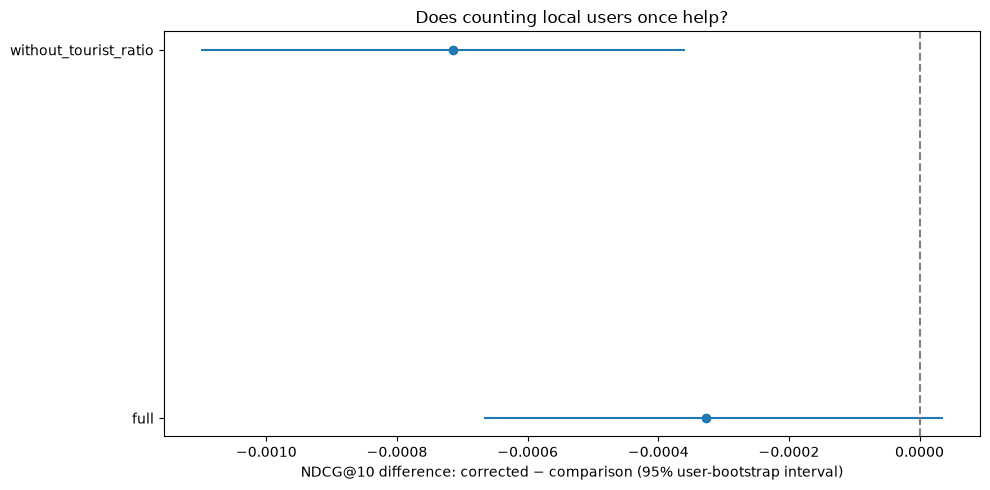

In [7]:
if (RATIO_OUT / "fold_scores.csv").exists() and (RATIO_OUT / "paired_trip_scores.parquet").exists():
    scores = pd.read_csv(RATIO_OUT / "fold_scores.csv")
    paired = pd.read_parquet(RATIO_OUT / "paired_trip_scores.parquet")
    display(scores[["fold", "variant", "ndcg_10", "recall_10", "coverage_10", "diversity_10", "seconds"]])
    display(scores.groupby("variant")[["ndcg_10", "recall_10"]].agg(["mean", "std"]))
    full = paired[paired.variant == "corrected_tourist_ratio"]
    comparisons = []
    for variant in sorted(set(paired.variant) - {"corrected_tourist_ratio"}):
        other = paired[paired.variant == variant]
        delta = full.merge(other, on=["fold", "trip_id", "user_id", "dest_region_id"],
                           suffixes=("_full", "_other"), validate="one_to_one")
        delta["difference"] = delta.ndcg_10_full - delta.ndcg_10_other
        users = delta.groupby("user_id")["difference"].agg(["sum", "count"])
        rng = np.random.default_rng(RANDOM_SEED)
        samples = []
        for _ in range(BOOTSTRAP_REPEATS):
            selected = users.iloc[rng.integers(0, len(users), size=len(users))]
            samples.append(selected["sum"].sum() / selected["count"].sum())
        low, high = np.quantile(samples, [0.025, 0.975])
        fold_deltas = delta.groupby("fold")["difference"].mean()
        comparisons.append({"comparison": variant, "ndcg_difference": delta.difference.mean(),
            "low_95": low, "high_95": high, "folds_improved": int((fold_deltas > 0).sum()),
            "folds_tested": len(fold_deltas),
            "evidence": "supports corrected" if low > 0 else "supports comparison" if high < 0 else "uncertain"})
    differences = pd.DataFrame(comparisons)
    display(differences)
    differences.to_csv(RATIO_OUT / "comparison_summary.csv", index=False)
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.errorbar(differences.ndcg_difference, differences.comparison,
                xerr=[differences.ndcg_difference-differences.low_95,
                      differences.high_95-differences.ndcg_difference], fmt="o")
    ax.axvline(0, color="gray", linestyle="--")
    ax.set(xlabel="NDCG@10 difference: corrected − comparison (95% user-bootstrap interval)",
           ylabel="", title="Does counting local users once help?")
    fig.tight_layout()
    fig.savefig(RATIO_OUT / "feature_comparison.png", dpi=160)
    plt.show()
else:
    print("Not measured yet. Run complete comparisons before drawing conclusions.")


## 13. What the tourist-ratio test tells us

**The repeated counting is confirmed.** In fold 0, 7,902,826 local history rows represent 1,658,585 distinct training user–POI pairs (about 4.8 appearances per pair). All five folds show similar repetition. The small-example tests pass, and each fold's reconstructed current ratio matches the loaded feature values.

Completed 15 model fits, preserving the previous folds, candidates, model settings, and training sample. Current-ratio reference scores exactly reproduce the earlier experiment.

| Ratio used | Mean NDCG@10 | Mean Recall@10 |
| --- | --- | --- |
| Current, repeated local rows | 0.25154 | 0.33453 |
| Corrected, each local user–POI once | 0.25121 | 0.33510 |
| No tourist-ratio feature | 0.25193 | 0.33497 |

**What this means:** the correction makes local-user counting consistent, but it did not demonstrate a ranking-quality gain. NDCG is slightly lower and Recall is slightly higher. The corrected-versus-current NDCG uncertainty interval includes zero; the correction wins on only 2/5 folds. Corrected ratio also has a lower average NDCG than omitting ratio, although it wins on 3/5 folds.

**Recommendation:** do not keep repeated counting simply because its score is slightly higher. If ratio is used, define its counts explicitly and use the corrected local-user interpretation. Before deciding to keep or remove the ratio, confirm corrected versus omitted with more training data and fresh seeds. These are exploratory comparisons on previously inspected folds, not untouched final-test evidence.

No shared feature, ranking, retrieval, or model artifact was changed. The correction exists only in this experiment. Reports: `reports/feature_experiments/tourist_ratio_unique_locals_all_folds/`.


## 14. Test the simpler model with more training data

Compare the full model against removal of all four place-context columns: tourist ratio, distance, destination category share, and destination city size.

Increase the training sample from 2,000 to **10,000 records per fold**. Some records lack a positive/negative candidate pair and cannot train LambdaRank; record the actual number used. Both variants use exactly the same eligible training rows, validation candidates, and model parameters within each fold. No features outside this group change.

This is a five-fold follow-up on previously inspected validation users, not a new final test. It tests whether the small-sample result holds up with more training data. No shared ranking feature list will be edited automatically.


In [4]:
RUN_BULK_EXPERIMENTS = False  # Completed outputs are saved below.
BULK_OUT = ROOT / "reports" / "feature_experiments" / "place_context_10000_all_folds"
BULK_TRAIN_SAMPLE_TRIPS = 10_000
BULK_GROUPS = {"place_context": ["tourist_ratio", "dist_to_center_km", "dest_cat_supply_share", "dest_city_total_pois"]}
BULK_VARIANTS = ["full", "without_place_context"]

def bulk_variant_matrix(frame, features, variant):
    columns = [name for name in features if name != "dest_month"]
    if variant == "without_place_context":
        columns = [name for name in columns if name not in BULK_GROUPS["place_context"]]
    return frame[columns].copy()


In [5]:
results, paired_tables, quality_tables, example_tables = [], [], [], []
if RUN_BULK_EXPERIMENTS:
    if not readiness["ready"].all():
        raise FileNotFoundError("Complete the input-readiness table before training.")
    if BULK_OUT.exists():
        raise FileExistsError(f"Choose a new RUN_NAME; {BULK_OUT} already exists.")
    BULK_OUT.mkdir(parents=True)
    manifest = {
        "git_commit": subprocess.check_output(["git", "rev-parse", "HEAD"], text=True).strip(),
        "working_tree": subprocess.check_output(["git", "status", "--porcelain"], text=True),
        "folds": FOLDS, "training_trip_sample": BULK_TRAIN_SAMPLE_TRIPS, "parameters": PARAMS,
        "variants": BULK_VARIANTS, "groups": BULK_GROUPS, "candidate_pattern": CANDIDATE_PATTERN,
        "versions": {name: importlib.metadata.version(name) for name in ["lightgbm", "pandas", "duckdb", "numpy"]},
        "inputs": {key: {"path": str(path), "bytes": path.stat().st_size,
                          "modified_ns": path.stat().st_mtime_ns} for key, path in required.items()},
    }
    (BULK_OUT / "settings.json").write_text(json.dumps(manifest, indent=2))
    for fold in FOLDS:
        train, val, feature_names = load_joined_matrix(
            DATA_GOLD_DIR / CANDIDATE_PATTERN.format(fold=fold), fold,
            BULK_TRAIN_SAMPLE_TRIPS, gold_dir=DATA_GOLD_DIR)
        summary = train.groupby("trip_id", sort=False)["label"].agg(["size", "sum"])
        usable = summary["sum"].between(1, summary["size"] - 1)
        train = train[train["trip_id"].isin(summary.index[usable])].reset_index(drop=True)
        groups = train.groupby("trip_id", sort=False).size().to_numpy()
        if not len(groups):
            raise ValueError("No training groups contain both positive and negative candidates.")
        quality = pd.DataFrame({"feature": feature_names,
            "missing_fraction": train[feature_names].isna().mean().to_numpy(),
            "distinct_values": train[feature_names].nunique().to_numpy()}).assign(fold=fold)
        quality_tables.append(quality)
        print(f"Loaded fold {fold}: {len(train):,} training rows; {len(val):,} validation rows.")
        for variant in BULK_VARIANTS:
            if variant.startswith("without_") and not set(BULK_GROUPS[variant[8:]]) & set(feature_names):
                continue
            started = time.perf_counter()
            x_train = bulk_variant_matrix(train, feature_names, variant)
            x_val = bulk_variant_matrix(val, feature_names, variant)
            model = lgb.LGBMRanker(**PARAMS)
            model.fit(x_train, train["label"], group=groups, eval_at=(10,))
            predictions = val[["trip_id", "poi_id"]].assign(score=model.predict(x_val))
            with TemporaryDirectory(dir=BULK_OUT) as temporary:
                path = Path(temporary) / "predictions.parquet"
                predictions.to_parquet(path, index=False)
                official = evaluate_predictions(path, fold=fold)
            per_trip = per_trip_metrics(predictions, fold)
            assert np.isclose(per_trip.ndcg_10.mean(), official["ndcg_10"], atol=5.1e-6, rtol=0)
            assert np.isclose(per_trip.recall_10.mean(), official["recall_10"], atol=5.1e-6, rtol=0)
            paired_tables.append(per_trip.assign(fold=fold, variant=variant))
            # Fixed example trips selected by ID, not by which variant looks better.
            example_ids = sorted(val.trip_id.unique())[:3]
            examples = predictions[predictions.trip_id.isin(example_ids)].sort_values(
                ["trip_id", "score", "poi_id"], ascending=[True, False, True])
            examples = examples.groupby("trip_id", sort=False).head(10).copy()
            examples["rank"] = examples.groupby("trip_id").cumcount() + 1
            example_tables.append(examples.assign(fold=fold, variant=variant))
            results.append({"fold": fold, "variant": variant, **official,
                            "features": x_train.shape[1], "training_trips": len(groups),
                            "seconds": time.perf_counter() - started})
            pd.DataFrame(results).to_csv(BULK_OUT / "fold_scores.csv", index=False)
            print(f"Fold {fold}: {variant}: NDCG@10={official['ndcg_10']:.5f}")
        del train, val, x_train, x_val, predictions, model
        # Save completed folds as checkpoints during the longer multi-fold run.
        pd.concat(paired_tables).to_parquet(BULK_OUT / "paired_trip_scores.parquet", index=False)
        pd.concat(quality_tables).to_csv(BULK_OUT / "feature_quality.csv", index=False)
        pd.concat(example_tables).to_parquet(BULK_OUT / "example_rankings.parquet", index=False)
    pd.concat(paired_tables).to_parquet(BULK_OUT / "paired_trip_scores.parquet", index=False)
    pd.concat(quality_tables).to_csv(BULK_OUT / "feature_quality.csv", index=False)
    pd.concat(example_tables).to_parquet(BULK_OUT / "example_rankings.parquet", index=False)
else:
    print("Experiments are disabled. No usefulness claims or experiment reports have been generated.")


Candidate schema: trip_id BIGINT, user_id BIGINT, fold BIGINT, dest_region_id VARCHAR, dest_month INTEGER, n_history_cities BIGINT, n_history_pois BIGINT, poi_id VARCHAR, stage1_score DOUBLE, stage1_rank BIGINT
 fold  gold_trips  candidate_trips    rows  min_per_trip  median_per_trip  max_per_trip  trips_with_10
    0       89201            89201 8880988            51            100.0           100          89201
    1       88857            88857 8847370            51            100.0           100          88857
    2       87954            87954 8755694            51            100.0           100          87954
    3       90255            90255 8986223            51            100.0           100          90255
    4       88551            88551 8816564            51            100.0           100          88551


Loaded fold 0: 887,228 training rows; 8,880,988 validation rows.


Fold 0: full: NDCG@10=0.27478


Fold 0: without_place_context: NDCG@10=0.27421


Candidate schema: trip_id BIGINT, user_id BIGINT, fold BIGINT, dest_region_id VARCHAR, dest_month INTEGER, n_history_cities BIGINT, n_history_pois BIGINT, poi_id VARCHAR, stage1_score DOUBLE, stage1_rank BIGINT
 fold  gold_trips  candidate_trips    rows  min_per_trip  median_per_trip  max_per_trip  trips_with_10
    0       89201            89201 8880988            51            100.0           100          89201
    1       88857            88857 8847370            51            100.0           100          88857
    2       87954            87954 8755694            51            100.0           100          87954
    3       90255            90255 8986223            51            100.0           100          90255
    4       88551            88551 8816564            51            100.0           100          88551


Loaded fold 1: 889,209 training rows; 8,847,370 validation rows.


... (10 outputs left out)

Candidate schema: trip_id BIGINT, user_id BIGINT, fold BIGINT, dest_region_id VARCHAR, dest_month INTEGER, n_history_cities BIGINT, n_history_pois BIGINT, poi_id VARCHAR, stage1_score DOUBLE, stage1_rank BIGINT
 fold  gold_trips  candidate_trips    rows  min_per_trip  median_per_trip  max_per_trip  trips_with_10
    0       89201            89201 8880988            51            100.0           100          89201
    1       88857            88857 8847370            51            100.0           100          88857
    2       87954            87954 8755694            51            100.0           100          87954
    3       90255            90255 8986223            51            100.0           100          90255
    4       88551            88551 8816564            51            100.0           100          88551


Loaded fold 4: 885,748 training rows; 8,816,564 validation rows.


Fold 4: full: NDCG@10=0.27724


Fold 4: without_place_context: NDCG@10=0.27727


## 15. Larger-sample results

The uncertainty chart uses **full minus simplified** NDCG@10. Negative means the simpler model scores better. Check Recall@10 as well, fold consistency, and the size of the change—not just whether an interval crosses zero.


,fold,variant,ndcg_10,recall_10,coverage_10,diversity_10,seconds
0,0,full,0.27478,0.35601,0.05952,5.941,12.694181
1,0,without_place_context,0.27421,0.35613,0.06026,5.898,12.097253
2,1,full,0.27661,0.35598,0.06054,5.930,12.320561
3,1,without_place_context,0.27650,0.35620,0.06251,5.881,12.353916
4,2,full,0.27854,0.36057,0.06135,5.953,12.545367
5,2,without_place_context,0.27854,0.36033,0.06103,5.864,12.088589
6,3,full,0.27409,0.35504,0.05986,5.966,12.575980
7,3,without_place_context,0.27444,0.35524,0.06140,5.878,12.656449
8,4,full,0.27724,0.35828,0.05993,5.947,12.450956
9,4,without_place_context,0.27727,0.35912,0.06076,5.926,12.100701


ndcg_10           recall_10          
                           mean       std      mean       std
variant                                                      
full                   0.276252  0.001815  0.357176  0.002241
without_place_context  0.276192  0.001855  0.357404  0.002194

,comparison,ndcg_difference,low_95,high_95,folds_improved,folds_tested,evidence
0,without_place_context,0.00006,-0.000233,0.000332,2,5,uncertain


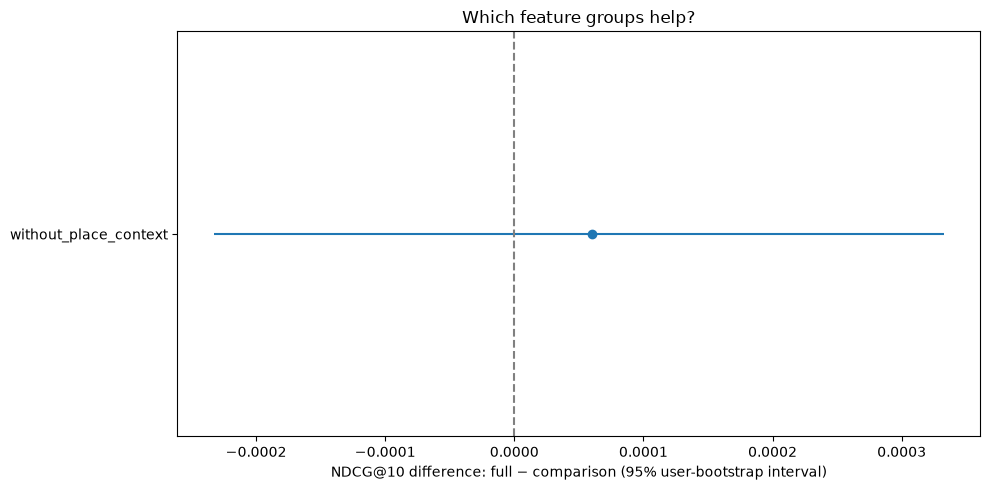

In [6]:
if (BULK_OUT / "fold_scores.csv").exists() and (BULK_OUT / "paired_trip_scores.parquet").exists():
    scores = pd.read_csv(BULK_OUT / "fold_scores.csv")
    paired = pd.read_parquet(BULK_OUT / "paired_trip_scores.parquet")
    display(scores[["fold", "variant", "ndcg_10", "recall_10", "coverage_10", "diversity_10", "seconds"]])
    display(scores.groupby("variant")[["ndcg_10", "recall_10"]].agg(["mean", "std"]))
    full = paired[paired.variant == "full"]
    comparisons = []
    for variant in sorted(set(paired.variant) - {"full"}):
        other = paired[paired.variant == variant]
        delta = full.merge(other, on=["fold", "trip_id", "user_id", "dest_region_id"],
                           suffixes=("_full", "_other"), validate="one_to_one")
        delta["difference"] = delta.ndcg_10_full - delta.ndcg_10_other
        users = delta.groupby("user_id")["difference"].agg(["sum", "count"])
        rng = np.random.default_rng(RANDOM_SEED)
        samples = []
        for _ in range(BOOTSTRAP_REPEATS):
            selected = users.iloc[rng.integers(0, len(users), size=len(users))]
            samples.append(selected["sum"].sum() / selected["count"].sum())
        low, high = np.quantile(samples, [0.025, 0.975])
        fold_deltas = delta.groupby("fold")["difference"].mean()
        comparisons.append({"comparison": variant, "ndcg_difference": delta.difference.mean(),
            "low_95": low, "high_95": high, "folds_improved": int((fold_deltas > 0).sum()),
            "folds_tested": len(fold_deltas),
            "evidence": "supports full" if low > 0 else "supports comparison" if high < 0 else "uncertain"})
    differences = pd.DataFrame(comparisons)
    display(differences)
    differences.to_csv(BULK_OUT / "comparison_summary.csv", index=False)
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.errorbar(differences.ndcg_difference, differences.comparison,
                xerr=[differences.ndcg_difference-differences.low_95,
                      differences.high_95-differences.ndcg_difference], fmt="o")
    ax.axvline(0, color="gray", linestyle="--")
    ax.set(xlabel="NDCG@10 difference: full − comparison (95% user-bootstrap interval)",
           ylabel="", title="Which feature groups help?")
    fig.tight_layout()
    fig.savefig(BULK_OUT / "feature_comparison.png", dpi=160)
    plt.show()
else:
    print("Not measured yet. Run complete comparisons before drawing conclusions.")


In [7]:
if (BULK_OUT / "fold_scores.csv").exists():
    larger = pd.read_csv(BULK_OUT / "fold_scores.csv")
    smaller = pd.read_csv(ROOT / "reports" / "feature_experiments" / "feature_screen_all_folds" / "fold_scores.csv")
    smaller = smaller[smaller.variant.isin(BULK_VARIANTS)].assign(training_sample_budget=2_000)
    larger = larger.assign(training_sample_budget=BULK_TRAIN_SAMPLE_TRIPS)
    sample_comparison = pd.concat([smaller, larger], ignore_index=True)
    display(sample_comparison.groupby(["training_sample_budget", "variant"])[["ndcg_10", "recall_10", "training_trips"]].mean())
    sample_comparison.to_csv(BULK_OUT / "sample_size_comparison.csv", index=False)
    by_fold = larger.pivot(index="fold", columns="variant", values="ndcg_10")
    by_fold["simplified_minus_full"] = by_fold.without_place_context - by_fold.full
    display(by_fold)
    by_fold.to_csv(BULK_OUT / "fold_differences.csv")


ndcg_10  recall_10  \
training_sample_budget variant                                      
2000                   full                   0.251542   0.334526   
                       without_place_context  0.252646   0.336972   
10000                  full                   0.276252   0.357176   
                       without_place_context  0.276192   0.357404   

                                              training_trips  
training_sample_budget variant                                
2000                   full                           1795.4  
                       without_place_context          1795.4  
10000                  full                           8916.8  
                       without_place_context          8916.8

variant,full,without_place_context,simplified_minus_full
fold,,,
0,0.27478,0.27421,-0.00057
1,0.27661,0.27650,-0.00011
2,0.27854,0.27854,0.00000
3,0.27409,0.27444,0.00035
4,0.27724,0.27727,0.00003


## 16. What the larger training sample tells us

Completed ten fits: full and simplified models on five folds. The sample budget was 10,000 records per fold, with about 8,917 usable ranking records per fold after excluding groups without positive/negative pairs. All 444,818 validation records were evaluated once across folds.

| Training sample budget | Full-model mean NDCG@10 | Without four context columns |
| --- | --- | --- |
| 2,000 | 0.25154 | 0.25265 |
| 10,000 | 0.27625 | 0.27619 |

At 10,000, mean Recall@10 was **0.35718** for full and **0.35740** for simplified. The NDCG difference (full minus simplified) was about **0.00006**, with a user-bootstrap 95% interval of **−0.00023 to +0.00033**. This run does not detect a clear difference; that is not a formal proof of equivalence.

Using the displayed five-decimal scores, simplified won two folds, full won two, and one was tied. The small-sample advantage from removing the group did not hold up with more training data. Both models benefited much more from additional training examples than from this feature choice.

**Decision:** removal is a possible simplification, not a demonstrated score improvement. If the team prefers fewer features, discuss an acceptable performance-loss margin and confirm the choice with fresh seeds or untouched evaluation data. Do not claim the four features are individually useless. No shared ranking code or model input list has been changed by this experiment.

Results and the earlier-sample comparison are saved in `reports/feature_experiments/place_context_10000_all_folds/`. Execution is disabled again to preserve outputs.
